In [1]:
!pip -q install pandas numpy scikit-learn matplotlib sentence-transformers

In [2]:

import pandas as pd
import numpy as np

rng = np.random.default_rng(42)

scam_templates = [
    "Your bank account requires verification immediately",
    "You have won a prize; claim it before it expires",
    "Your parcel is delayed; pay a fee to release it",
    "Your account will be blocked unless you verify your identity",
    "A suspicious transaction was detected; confirm your details",
    "Claim your reward by following the instructions now",
    "Your payment failed; submit your banking information",
    "You are eligible for a cash reward; register today",
    "Your subscription will expire; update payment details",
    "Urgent: confirm your account to avoid service suspension",
    "A refund is waiting; provide information to receive it",
    "Your wallet has been restricted; restore access now",
    "You have an unpaid toll; settle it immediately",
    "Your delivery address is invalid; pay to reschedule",
    "Your account has earned a bonus; withdraw it today",
    "A security alert requires immediate account confirmation",
    "Your tax refund is ready; provide details to receive it",
    "Your phone number won a giveaway; claim your gift",
    "Your loan has been approved; pay the processing charge",
    "Your account has unusual activity; verify your credentials",
    "An exclusive investment opportunity guarantees high returns",
    "Your membership reward is expiring; claim it now",
    "Your payment is on hold; confirm your identity",
    "You qualify for a grant; submit your personal details",
    "Your account access is at risk; act immediately",
    "A package awaits customs clearance; pay the requested fee",
    "Your card has been locked; verify details to reactivate it",
    "You have been selected for a cash giveaway",
    "Your invoice is overdue; use the payment instructions",
    "Your digital wallet needs verification to release funds",
]

safe_templates = [
    "Your bank statement is available in the official application",
    "Your parcel is scheduled for delivery tomorrow",
    "The meeting has been moved to the afternoon",
    "Your subscription renewal is confirmed",
    "Your payment receipt is available in your account",
    "The office will remain closed on the public holiday",
    "Your appointment is confirmed for next week",
    "Your monthly bill is ready to view",
    "The delivery agent will contact you on arrival",
    "Your class schedule has been updated",
    "The requested document is available for collection",
    "Your order has been dispatched successfully",
    "The maintenance work is scheduled for Sunday",
    "Your ticket booking has been confirmed",
    "Your account settings were updated successfully",
    "The library will close at six this evening",
    "Your refund has been processed successfully",
    "The team meeting will begin at ten tomorrow",
    "Your application status is available on the official portal",
    "Your monthly statement has been generated",
    "The package was delivered to the reception desk",
    "Your appointment reminder is for Friday morning",
    "The payment was received and recorded",
    "Your requested service is now active",
    "The timetable is available on the college website",
    "Your registration has been completed",
    "The invoice has been sent to your email address",
    "Your reservation is confirmed for the selected date",
    "The system update will begin tonight",
    "Your support request has been received",
]

def generate_messages(templates, label, prefix, variants=20):
    rows = []

    prefixes = [
        "Hello,", "Notice:", "Update:", "Dear customer,",
        "Reminder:", "Account message:", ""
    ]

    suffixes = [
        "Please review the message.",
        "Thank you for your attention.",
        "Further information is available in your account.",
        "Please check the relevant details.",
        "This message contains an account update.",
        ""
    ]

    for i, template in enumerate(templates):
        group_id = f"{prefix}_template_{i:02d}"

        for j in range(variants):
            text = (
                f"{rng.choice(prefixes)} {template}. "
                f"{rng.choice(suffixes)}"
            ).strip()

            rows.append({
                "text": text,
                "label": label,
                "group": group_id,
            })

    return rows

rows = (
    generate_messages(scam_templates, 1, "scam")
    + generate_messages(safe_templates, 0, "safe")
)

df = pd.DataFrame(rows)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df.to_csv("experiment2_synthetic.csv", index=False)

print("Dataset size:", len(df))
print("Unique template families:", df["group"].nunique())
print(df.groupby("label").size())
print(df.head())

from google.colab import files
files.download("experiment2_synthetic.csv")


Dataset size: 1200
Unique template families: 60
label
0    600
1    600
dtype: int64
                                                text  label             group
0  Update: The system update will begin tonight. ...      0  safe_template_28
1  Account message: Your ticket booking has been ...      0  safe_template_13
2  Dear customer, Claim your reward by following ...      1  scam_template_05
3  Dear customer, Your membership reward is expir...      1  scam_template_21
4  Hello, Your parcel is delayed; pay a fee to re...      1  scam_template_02


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Random split: 960 train; 240 test
Grouped split: 960 train; 240 test
Group overlap: 0
Loading pretrained text encoder...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/38 [00:00<?, ?it/s]


FULL RESULTS
  split                                   model  macro_f1  macro_precision  macro_recall  scam_pr_auc  train_size  test_size
 Random              TF-IDF Logistic Regression    1.0000           1.0000        1.0000        1.000         960        240
 Random                        TF-IDF LinearSVC    1.0000           1.0000        1.0000        1.000         960        240
 Random Pretrained MiniLM + Logistic Regression    0.9958           0.9959        0.9958        1.000         960        240
Grouped              TF-IDF Logistic Regression    0.9917           0.9918        0.9917        1.000         960        240
Grouped                        TF-IDF LinearSVC    1.0000           1.0000        1.0000        1.000         960        240
Grouped Pretrained MiniLM + Logistic Regression    0.9291           0.9316        0.9292        0.991         960        240

MACRO-F1 PERFORMANCE GAP
split                                    Grouped  Random  \
model                    

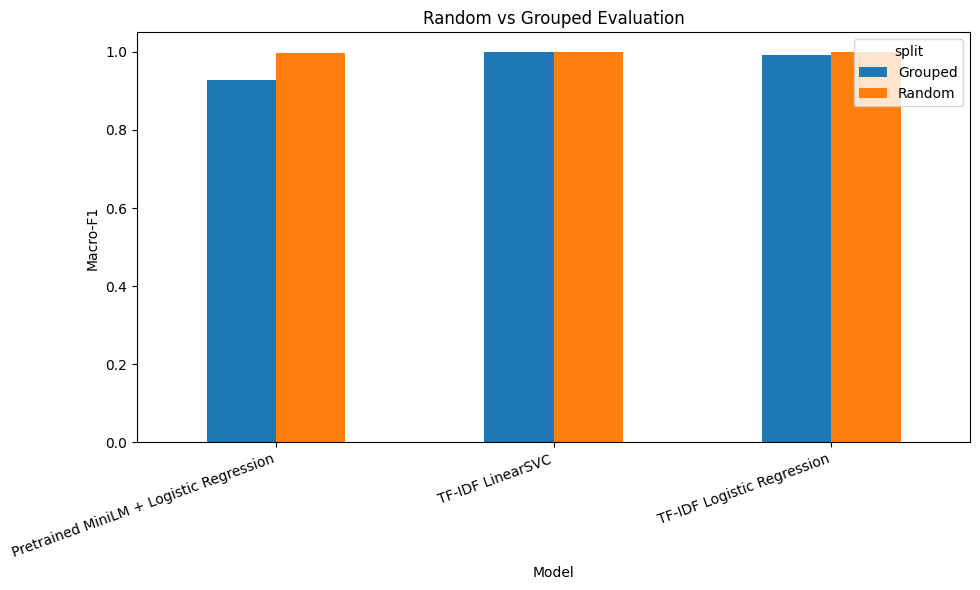

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    average_precision_score
)
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression as LR

df = pd.read_csv("experiment2_synthetic.csv")

X = df["text"].astype(str).to_numpy()
y = df["label"].astype(int).to_numpy()
groups = df["group"].to_numpy()
indices = np.arange(len(df))

# Random split: same template families can occur in both partitions.
random_train, random_test = train_test_split(
    indices, test_size=0.20, random_state=42, stratify=y
)

# Group split: no template family can appear in both partitions.
splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

group_train, group_test = next(
    splitter.split(X, y, groups)
)

assert set(groups[group_train]).isdisjoint(set(groups[group_test]))

print("Random split:", len(random_train), "train;",
      len(random_test), "test")
print("Grouped split:", len(group_train), "train;",
      len(group_test), "test")
print("Group overlap:", len(set(groups[group_train]) &
                             set(groups[group_test])))

def make_lr():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=1,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])

def make_svc():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=1,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=42
        ))
    ])

print("Loading pretrained text encoder...")
encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# The encoder is pretrained. Its weights are not fine-tuned here.
# Embeddings are calculated independently for each message.
embeddings = encoder.encode(
    X.tolist(),
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

def evaluate(name, train_idx, test_idx):
    y_train, y_test = y[train_idx], y[test_idx]
    records = []

    models = [
        ("TF-IDF Logistic Regression", make_lr(), X),
        ("TF-IDF LinearSVC", make_svc(), X),
        ("Pretrained MiniLM + Logistic Regression", None, embeddings)
    ]

    for model_name, model, data in models:
        if model is None:
            model = LR(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
            model.fit(data[train_idx], y_train)
            pred = model.predict(data[test_idx])
            scores = model.decision_function(data[test_idx])
        else:
            model.fit(data[train_idx].tolist(), y_train)
            pred = model.predict(data[test_idx].tolist())
            scores = model.decision_function(data[test_idx].tolist())

        records.append({
            "split": name,
            "model": model_name,
            "macro_f1": f1_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "macro_precision": precision_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "macro_recall": recall_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "scam_pr_auc": average_precision_score(y_test, scores),
            "train_size": len(train_idx),
            "test_size": len(test_idx)
        })

    return records

results = []

results.extend(evaluate(
    "Random", random_train, random_test
))

results.extend(evaluate(
    "Grouped", group_train, group_test
))

results = pd.DataFrame(results)

# Positive gap means random-split performance is higher.
gap = results.pivot(
    index="model", columns="split", values="macro_f1"
)
gap["random_minus_grouped_f1"] = gap["Random"] - gap["Grouped"]

results.to_csv("experiment2_results.csv", index=False)
gap.to_csv("experiment2_performance_gaps.csv")

print("\nFULL RESULTS")
print(results.round(4).to_string(index=False))

print("\nMACRO-F1 PERFORMANCE GAP")
print(gap.round(4))

# Comparison chart
chart_data = results.pivot(
    index="model", columns="split", values="macro_f1"
)

ax = chart_data.plot(kind="bar", figsize=(10, 6))
ax.set_ylabel("Macro-F1")
ax.set_xlabel("Model")
ax.set_title("Random vs Grouped Evaluation")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("experiment2_macro_f1.png", dpi=300)
plt.show()

from google.colab import files
files.download("experiment2_results.csv")
files.download("experiment2_performance_gaps.csv")
files.download("experiment2_macro_f1.png")


In [4]:

import pandas as pd
import urllib.request
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

with urllib.request.urlopen(url) as response:
    archive_bytes = response.read()

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    raw = archive.read("SMSSpamCollection").decode("utf-8")

rows = [line.split("\t", 1) for line in raw.splitlines()]
rows = [row for row in rows if len(row) == 2]

real_df = pd.DataFrame(rows, columns=["label", "text"])

real_df["label"] = real_df["label"].map({
    "ham": 0,
    "spam": 1
})

real_df = real_df.dropna()
real_df = real_df.drop_duplicates(subset=["text"])
real_df = real_df.reset_index(drop=True)

real_df.to_csv("uci_sms_clean.csv", index=False)

print("Dataset size:", len(real_df))
print("\nClass counts:")
print(real_df["label"].value_counts().rename(
    index={0: "Safe (ham)", 1: "Spam"}
))
print("\nSample messages:")
print(real_df.head())


Dataset size: 5171

Class counts:
label
Safe (ham)    4518
Spam           653
Name: count, dtype: int64

Sample messages:
   label                                               text
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    average_precision_score, classification_report
)
from sentence_transformers import SentenceTransformer
import pandas as pd

texts = real_df["text"].tolist()
labels = real_df["label"].astype(int).to_numpy()

train_idx, test_idx = train_test_split(
    range(len(real_df)),
    test_size=0.20,
    random_state=42,
    stratify=labels
)

X_train = [texts[i] for i in train_idx]
X_test = [texts[i] for i in test_idx]
y_train = labels[train_idx]
y_test = labels[test_idx]

models = {
    "TF-IDF Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("model", LogisticRegression(
            max_iter=2000, random_state=42
        ))
    ]),
    "TF-IDF LinearSVC": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("model", LinearSVC(random_state=42))
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    scores = model.decision_function(X_test)

    results.append({
        "model": name,
        "macro_f1": f1_score(
            y_test, predictions, average="macro"
        ),
        "macro_precision": precision_score(
            y_test, predictions, average="macro",
            zero_division=0
        ),
        "macro_recall": recall_score(
            y_test, predictions, average="macro",
            zero_division=0
        ),
        "spam_pr_auc": average_precision_score(
            y_test, scores
        )
    })

# Pretrained MiniLM embeddings + Logistic Regression
encoder = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

train_embeddings = encoder.encode(
    X_train, batch_size=32, show_progress_bar=True
)
test_embeddings = encoder.encode(
    X_test, batch_size=32, show_progress_bar=True
)

mini_model = LogisticRegression(max_iter=2000, random_state=42)
mini_model.fit(train_embeddings, y_train)

predictions = mini_model.predict(test_embeddings)
scores = mini_model.decision_function(test_embeddings)

results.append({
    "model": "Pretrained MiniLM + Logistic Regression",
    "macro_f1": f1_score(
        y_test, predictions, average="macro"
    ),
    "macro_precision": precision_score(
        y_test, predictions, average="macro",
        zero_division=0
    ),
    "macro_recall": recall_score(
        y_test, predictions, average="macro",
        zero_division=0
    ),
    "spam_pr_auc": average_precision_score(
        y_test, scores
    )
})

results_df = pd.DataFrame(results)
results_df.to_csv("experiment2_uci_results.csv", index=False)

print(results_df.round(4).to_string(index=False))
print("\nDetailed report for MiniLM:")
print(classification_report(
    y_test, predictions,
    target_names=["ham", "spam"],
    zero_division=0
))

from google.colab import files
files.download("experiment2_uci_results.csv")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/130 [00:00<?, ?it/s]

Batches:   0%|          | 0/33 [00:00<?, ?it/s]

                                  model  macro_f1  macro_precision  macro_recall  spam_pr_auc
             TF-IDF Logistic Regression    0.8842           0.9763        0.8282       0.9585
                       TF-IDF LinearSVC    0.9545           0.9745        0.9367       0.9774
Pretrained MiniLM + Logistic Regression    0.9425           0.9676        0.9209       0.9730

Detailed report for MiniLM:
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       904
        spam       0.96      0.85      0.90       131

    accuracy                           0.98      1035
   macro avg       0.97      0.92      0.94      1035
weighted avg       0.98      0.98      0.98      1035



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>